# Practice Session 03: Find near-duplicates using shingling

Author: <font color="#2680EB">Anna Quílez Rodríguez</font>

E-mail: <font color="#2680EB">anna.quilez01@estudiant.upf.edu</font>

AI used: <font color="#2680EB">ChatGPT. I used artificial intelligence to help me understand the functions I wasn’t familiar with and to write some of the code.</font>

Date: <font color="#2680EB">8/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import gzip
import csv
import re
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Romanization library
from transliterate import translit
from transliterate.exceptions import LanguageDetectionError

# Timing
from timeit import default_timer as timer


In [ ]:
# LEAVE AS-IS

# Input file
INPUT_FILENAME = "questions.csv.gz"

# Minimum number of words needed to read the questions
MIN_WORDS = 20

# IMPORTANT:
# 1. Set this to 2000 during development
# 2. Set this to 10000 once you have completed the development
MAX_QUESTIONS = 2000

# Array for storing questions
questions = []

with gzip.open(INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    
    questions_read = 0
    reader = csv.DictReader(input_file)
    headers = reader.fieldnames
    
    for line in reader:
            
        # Read line
        q1 = line["question1"]
        q2 = line["question2"]
        
        if min(len(q1.split()), len(q2.split())) >= MIN_WORDS:
            questions.append(q1)
            questions.append(q2)
            
            questions_read += 2
        
            if (MAX_QUESTIONS != -1) and (questions_read >= MAX_QUESTIONS):
                break

print(f"Read {len(questions)} questions")

Read 10000 questions


In [3]:
# LEAVE AS-IS

SAMPLE_SIZE = 3

for question in random.sample(questions, SAMPLE_SIZE):
    print(question)
    print()

How good are the package European trips offered by OTAs like MakeMyTrip or Yatra? Are they upfront about the costs or are there any hidden costs too?

If the United States has a female president, will her husband be called the first gentleman? What will Bill Clinton be called if Hillary is elected?

How introducing 2000 Rs notes which is of higher denomination than the current highest denomination 1000 Rs notes will reduce the black money?



# 1. Auxiliary functions <font color="#2680EB">[5%]</font>

<font size="+1" color="#2680EB">**Indicate how would you handle the case in which both lists are empty.** Include a justification, ideally a reference, justifying your choice.</font>

**Answer.** If both lists are empty:

* If both lists are empty, the two sets are the same because they contain exactly the same elements (none). However, the Jaccard formula gives 0/0, which is undefined, so we define the similarity as 1.0 since the sets are identical.

<font size="+1" color="#2680EB">**Implement Jaccard similarity of lists.** Be consistent with your choice of handling of empty lists.</font>

In [4]:
def jaccard_similarity(list1, list2):
    
    # YOUR CODE HERE
    set1, set2 = set(list1), set(list2)
    intersection = set1.intersection(set2)
    union = set1.union(set2)
    
    if len(union) == 0:
        return 1.0
    sim = len(intersection) / len(union)
    
    return sim


<font size="+1" color="#2680EB">**Test your Jaccard similarity function,** with at least the test cases described above.</font>

In [5]:
# YOUR CODE HERE
#test 1 empty 
assert jaccard_similarity([], []) == 1.0
# test 2 : identical 
assert jaccard_similarity(['a', 'b'], ['a', 'b']) == 1.0
# test 3: 1/6 (Intersection=1, Union=6)
assert abs(jaccard_similarity(['a', 'b', 'c', 'd'], ['a', 'e', 'f']) - 1/6) < 0.001

<font size="+1" color="#2680EB">**Implement your text cleaning function**</font>

In [6]:
def clean(text):
    text = text.lower()
    
    # YOUR CODE HERE
    try: 
        text = translit(text, reversed=True) 
    except LanguageDetectionError: 
        pass 
    text = text.strip() 
    text = re.sub(r'[^a-z0-9 ]', '', text) 
    text = re.sub(r' +', ' ', text)
    return text

<font size="+1" color="#2680EB">**Test your text cleaning function.** Use [assert](https://realpython.com/python-assert-statement/), and cover all cases of the specification. Make sure your test cases are similar to questions in the dataset.</font>

In [7]:
# YOUR CODE HERE
assert clean("  HOLA   MUNDO!! ") == "hola mundo"
assert clean("Año 2024...") == "ano 2024"
assert clean("www.google.com") == "wwwgooglecom"
assert clean("How Are You?") == "how are you"
assert clean("Python, Java and C++") == "python java and c"



# 2. Implement an n-gram extractor <font color="#2680EB">[5%]</font>

<font size="+1" color="#2680EB">**Implement the ngram extractor.**</font>

In [8]:
MIN_TOKEN_LENGTH = 4

def ngrams(text, size):
    #AI
    # YOUR CODE HERE 
    words = [word for word in text.split() if len(word) >= MIN_TOKEN_LENGTH]
    
    ngrams = []
    
    for i in range(len(words) - size + 1):
        ngram = " ".join(words[i:i+size])
        ngrams.append(ngram)
    
    
    return(ngrams)

<font size="+1" color="#2680EB">**Test your function 'ngrams'**. Consider ngrams of size 3, select three questions from the dataset, and check their ngrams using assert.</font>

In [9]:
# YOUR CODE HERE
# Test the ngrams function with a simple example
test_text = "this is a beautiful test sentence for checking ngrams"
result = ngrams(test_text, 3)

assert isinstance(result, list)
assert all(isinstance(ng, str) for ng in result)
assert len(result) == 4
assert result[0] == "this beautiful test"
assert result[-1] == "sentence checking ngrams"

#dataset
for q in questions[:3]:
    ng = ngrams(q, 3)
    assert isinstance(ng, list)
    assert all(isinstance(x, str) for x in ng)

# 3. Estimation of brute force all-pairs method  <font color="#2680EB">[10%]</font>

In [10]:
# LEAVE AS-IS

def time_brute_force_similarities(texts, limit, ngram_size):
    if limit > len(texts):
        raise ValueError("Limit should be less than or equal than the number of texts")
        
    # Start a timer
    start = timer()

    # Iterate through document identifiers
    for docid1 in range(np.min([len(texts), limit])):

        # Extract ngrams from doc1
        doc1 = texts[docid1]
        ngrams1 = ngrams(doc1, ngram_size)

        # Iterate through document identifiers larger than doc2
        for docid2 in range(docid1+1, np.min([len(questions), limit])):
                         
            # Extract ngrams from doc2
            doc2 = texts[docid2]
            ngrams2 = ngrams(doc2, ngram_size)

            # Compute similarity
            similarity = jaccard_similarity(ngrams1, ngrams2)

    end = timer()
    return(end - start)

<font size="+1" color="#2680EB">**Generate the data for the requested plots**.</font>

In [11]:
num_texts = []
time_required = []

# YOUR CODE HERE  
for n in range(1, 1002, 200):   # 1, 201, 401, 601, 801, 1001
    t = time_brute_force_similarities(questions, n, ngram_size=3)
    num_texts.append(n)
    time_required.append(t)
    print(f"n={n}: {t:.4f} s")


n=1: 0.0001 s
n=201: 0.1154 s
n=401: 0.4638 s
n=601: 1.0447 s
n=801: 1.7657 s
n=1001: 2.6491 s


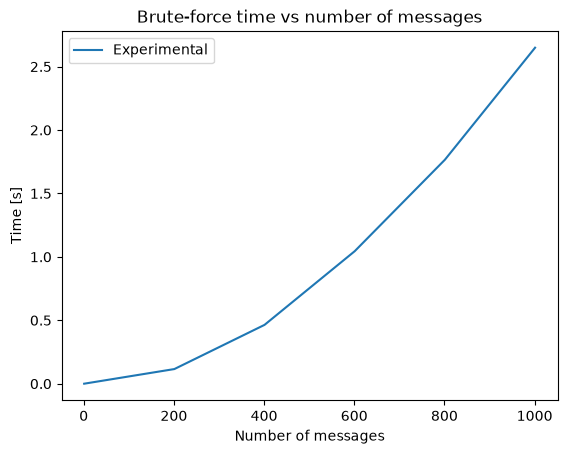

In [12]:
# Now plot this data; remember to add a title and label for the x and y axis.
#AI
# YOUR CODE HERE
sns.lineplot(x=num_texts, y=time_required, label="Experimental")
plt.xlabel('Number of messages')
plt.ylabel('Time [s]')
plt.title('Brute-force time vs number of messages')
plt.legend()
plt.show()


<font size="+1" color="#2680EB">**Find a quadratic approximation of the required time for bruteforce**. Use two significant digits for the coefficient. The code will plot your estimation and the experimental value.</font>

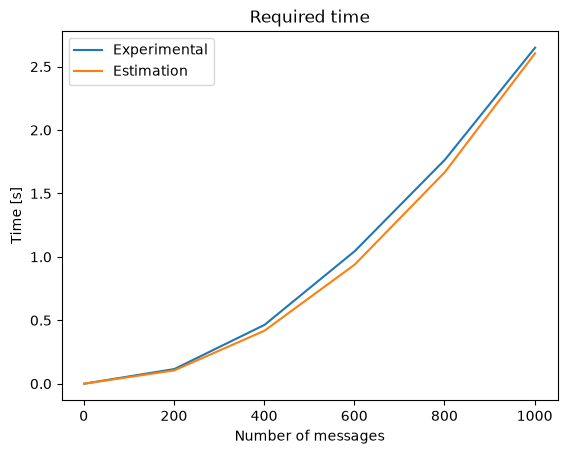

In [13]:
# YOUR CODE HERE

a = time_required[-1] / (num_texts[-1] ** 2)
a = float(f"{a:.2g}") #two significant digits

time_estimated = [a * (n**2.0) for n in num_texts]

sns.lineplot(x=num_texts, y=time_required, label="Experimental")
sns.lineplot(x=num_texts, y=time_estimated, label="Estimation")

plt.xlabel('Number of messages')
plt.ylabel('Time [s]')
_ = plt.title('Required time')

<font size="+1" color="#2680EB">**Estimate how long the brute-force approach would take for the entire dataset**. It contains 25K questions. Express your estimation first in seconds, and then in human terms (e.g., hours, or days) using [timedelta](https://docs.python.org/3/library/datetime.html#timedelta-objects) and [humanize](https://pypi.org/project/humanize/).</font>

In [14]:
from datetime import timedelta
import humanize

# YOUR CODE HERE
N = 25000
estimated_seconds = a * (N ** 2.0)

print(f"Estimated time: {estimated_seconds:.2f} seconds")
print(f"In human terms: {humanize.naturaldelta(timedelta(seconds=estimated_seconds))}")  

Estimated time: 1625.00 seconds
In human terms: 27 minutes


# 4. Computing the doc-ngram matrix <font color="#2680EB">[20%]</font>

## 4.1 Create list of all ngrams

<font size="+1" color="#2680EB">**Create an ngram_to_index dictionary**.</font>

In [38]:
NGRAM_SIZE = 3

ngram_to_index = {}
index_to_ngram = {}
next_index = 0

for question in questions:
    all_ngrams = ngrams(question, NGRAM_SIZE)
    
    # YOUR CODE HERE
    for ngram in all_ngrams:
        if ngram not in ngram_to_index:
            ngram_to_index[ngram] = next_index
            index_to_ngram[next_index] = ngram
            next_index += 1
            
num_distinct_ngrams = next_index

print(f"There are {num_distinct_ngrams} distinct ngrams in the {len(questions)} questions")

There are 96348 distinct ngrams in the 10000 questions


<font size="+1" color="#2680EB">**Write test_ngram_index_consistency**.</font>

In [39]:
def test_ngram_index_consistency(ngram_to_index, index_to_ngram, text):
    # YOUR CODE HERE
    all_ngrams = ngrams(text, NGRAM_SIZE)
    
    for ng in all_ngrams:
        if ng in ngram_to_index:
            index = ngram_to_index[ng]
            assert index_to_ngram[index] == ng
        else:
            print(f"Not in dictionary: '{ng}'")
    

test_ngram_index_consistency(ngram_to_index, index_to_ngram, "pending many days")
test_ngram_index_consistency(ngram_to_index, index_to_ngram, "answer this question")

Not in dictionary: 'pending many days'


## 2.2 Create table ngrams x documents

In [40]:
# LEAVE AS-IS

# Create dense matrix in which every cell contains the value "False"
M_ngram_doc = np.full((num_distinct_ngrams, len(questions)), False)

# Print the number of rows and columns of this matrix
# numpy.matrix.shape is a tuple (0=rows, 1=columns)
print(f"Matrix has {M_ngram_doc.shape[0]} rows (distinct shingles)")
print(f"Matrix has {M_ngram_doc.shape[1]} columns (distinct documents)")

Matrix has 96348 rows (distinct shingles)
Matrix has 10000 columns (distinct documents)


<font size="+1" color="#2680EB">**Fill-in the M_ngram_doc matrix**. Use the template below.</font>

In [41]:
for docid in range(len(questions)):
    question = questions[docid]
    all_ngrams = ngrams(question, NGRAM_SIZE)
    for ngram_str in all_ngrams:
        # YOUR CODE HERE
        ngram_index = ngram_to_index[ngram_str]
        M_ngram_doc[ngram_index, docid] = True
        

<font size="+1" color="#2680EB">**Print the density of the matrix**. This is the fraction of cells that are non-zero. Print this as a percentage, using 3 decimals.</font>

In [42]:
# YOUR CODE HERE
density = np.sum(M_ngram_doc) / M_ngram_doc.size * 100
print(f"Density: {density:.3f}%")

Density: 0.013%


In [43]:
# LEAVE AS-IS

test_docid=391
print(f"Positions of non-zeros in column of docid {test_docid} of M_ngram_doc")
print()

print(f"Clean text:\n {clean(questions[test_docid])}")
ngrams_doc_tested = [("%d (%s)" % (i, index_to_ngram[i])) for i in range(num_distinct_ngrams) if M_ngram_doc[i, test_docid] == True]

print()
print(f"Non-zeros in corresponding row:\n {ngrams_doc_tested}")


Positions of non-zeros in column of docid 391 of M_ngram_doc

Clean text:
 what would have happened if the japanese had not attacked pearl harbor would the us have still gotten into the war with germany

Non-zeros in corresponding row:
 ['4397 (What would have)', '4398 (would have happened)', '4399 (have happened Japanese)', '4400 (happened Japanese attacked)', '4401 (Japanese attacked Pearl)', '4402 (attacked Pearl Harbor?)', '4403 (Pearl Harbor? Would)', '4404 (Harbor? Would U.S.)', '4405 (Would U.S. have)', '4406 (U.S. have still)', '4407 (have still gotten)', '4408 (still gotten into)', '4409 (gotten into with)', '4410 (into with Germany?)']


# 3. Implement a permutation generator <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement the function "random_permutation"**. Follow the specification above.</font>

In [44]:
def random_permutation(k):
    # YOUR CODE HERE
    l = list(range(k))
    random.shuffle(l)
    return l

In [45]:
# LEAVE AS-IS

# Permute a list according to a permutation
def permuter(original_list, permutation):
    permuted_list = []
    for index in permutation:
        permuted_list.append(original_list[index])
    return permuted_list

# Code for testing permutations

# Original lists
original_list_1 = ["1 (test1)", "2 (test2)", "3 (test3)", "4 (test4)", "5 (test5)"]
original_list_2 = ["1 (alpha)", "2 (gamma)", "3 (beta)", "4 (delta)", "5 (epsilon)"]
assert len(original_list_1) == len(original_list_2)
lists_len = len(original_list_1)

print("Original:")
print(original_list_1)
print(original_list_2)
print()

# Two permutation tests
print("Permuted (first test):")
permutation_1 = random_permutation(lists_len)
print(permuter(original_list_1, permutation_1))
print(permuter(original_list_2, permutation_1))
print()

print("Permuted (second test)")
permutation_2 = random_permutation(lists_len)
print(permuter(original_list_1, permutation_2))
print(permuter(original_list_2, permutation_2))

Original:
['1 (test1)', '2 (test2)', '3 (test3)', '4 (test4)', '5 (test5)']
['1 (alpha)', '2 (gamma)', '3 (beta)', '4 (delta)', '5 (epsilon)']

Permuted (first test):
['4 (test4)', '1 (test1)', '5 (test5)', '2 (test2)', '3 (test3)']
['4 (delta)', '1 (alpha)', '5 (epsilon)', '2 (gamma)', '3 (beta)']

Permuted (second test)
['2 (test2)', '1 (test1)', '4 (test4)', '5 (test5)', '3 (test3)']
['2 (gamma)', '1 (alpha)', '4 (delta)', '5 (epsilon)', '3 (beta)']


# 4. Compute the signature of each document <font color="#2680EB">[20%]</font>

In [46]:
# LEAVE AS-IS

NUM_PERMUTATIONS = 5

permutations = []

# Create the permutations
for i in range(NUM_PERMUTATIONS):
    permutation = random_permutation(num_distinct_ngrams)
    permutations.append(random_permutation(num_distinct_ngrams))
    
# Visualize the permutations by printing their first 4 elements
for i in range(len(permutations)):
    permutation = permutations[i]
    print("Permutation %d: %d, %d, %d, %d, ..." % (i,
                permutation[0], permutation[1], permutation[2], permutation[3] ))

Permutation 0: 76066, 7232, 91161, 53147, ...
Permutation 1: 80364, 6792, 34117, 36818, ...
Permutation 2: 31735, 14631, 38031, 5037, ...
Permutation 3: 82253, 31777, 50408, 72785, ...
Permutation 4: 45620, 36410, 12645, 62568, ...


In [47]:
# LEAVE AS-IS

# Find the first ngram in a document, according to a permutation
def find_first_one(docid, permutation):

    # The instructor used AI to optimize this function (Gemini 3.6 Flash)
    
    # Extract the column docid in the order of the permutation
    matches = M_ngram_doc[permutation, docid]
    
    # Check if there are any "True" in the column
    if not matches.any():
        return -1
        
    # Function argmax returns the index of the first True value
    return permutation[np.argmax(matches)]

<font size="+1" color="#2680EB">**Implement code to create M_signature_doc**.</font>

In [49]:
# Create empty matrix
M_signature_doc = np.full((NUM_PERMUTATIONS, len(questions)), np.nan)

for permutation_num in range(NUM_PERMUTATIONS):
    print(f"Creating signatures for permutation {permutation_num+1} of {NUM_PERMUTATIONS}")
    permutation = permutations[permutation_num]
    
    start = timer()
    print(f"- There are {len(questions)} documents")
    # YOUR CODE HERE
    for docid in range(len(questions)):
        M_signature_doc[permutation_num, docid] = find_first_one(docid, permutation)
    elapsed = timer() - start
    print(f"  - Done in {elapsed:.2f} s")
# The code above should take less than 5 minutes for 10K documents


Creating signatures for permutation 1 of 5
- There are 10000 documents
  - Done in 32.37 s
Creating signatures for permutation 2 of 5
- There are 10000 documents
  - Done in 30.84 s
Creating signatures for permutation 3 of 5
- There are 10000 documents
  - Done in 30.82 s
Creating signatures for permutation 4 of 5
- There are 10000 documents
  - Done in 30.91 s
Creating signatures for permutation 5 of 5
- There are 10000 documents
  - Done in 31.04 s


In [50]:
# LEAVE AS-IS

def extract_ngrams(docid):
    return [x for x in range(num_distinct_ngrams) if M_ngram_doc[x, docid] == True]

def extract_signature(docid):
    return [M_signature_doc[x, docid] for x in range(NUM_PERMUTATIONS)]


In [51]:
# Pick two documents that are similar

TEST_DOCID_1 = 790
TEST_DOCID_2 = 791

# LEAVE AS-IS

def print_sig(texts, M_ngram_doc, M_signature_doc, i):
    print(f"Document #{i}")
    print(f"Text      : {texts[i]}")
    print(f"Clean     : {clean(texts[i])}")
    
    ngrams = extract_ngrams(i)
    signature = extract_signature(i)
    
    print(f"Ngrams    : {ngrams}")
    print(f"Signature : {signature}")
    
    return (ngrams, signature)

# Print two messages and their signatures

(ng1,sig1) = print_sig(questions, M_ngram_doc, M_signature_doc, TEST_DOCID_1 )
print()
(ng2,sig2) = print_sig(questions, M_ngram_doc, M_signature_doc, TEST_DOCID_2 )
print()

print(f"Ngrams similarity     : {jaccard_similarity(ng1,ng2)}")
print(f"Signatures similarity : {jaccard_similarity(sig1,sig2)}")

Document #790
Text      : Canada I get 10% vacation pay in lump sum once a year and it gets taxed 50% so say it was 8000 I get 4000? Is this right?
Clean     : canada i get 10 vacation pay in lump sum once a year and it gets taxed 50 so say it was 8000 i get 4000 is this right
Ngrams    : [8796, 8797, 8798, 8799, 8800, 8801, 8802, 8803, 8804]
Signature : [np.float64(8801.0), np.float64(8802.0), np.float64(8796.0), np.float64(8804.0), np.float64(8798.0)]

Document #791
Text      : Buying a car from different state in india and getting it registered in other state is it possible, will I have to pay taxes in both states?
Clean     : buying a car from different state in india and getting it registered in other state is it possible will i have to pay taxes in both states
Ngrams    : [8805, 8806, 8807, 8808, 8809, 8810, 8811, 8812, 8813, 8814, 8815, 8816, 8817]
Signature : [np.float64(8805.0), np.float64(8814.0), np.float64(8813.0), np.float64(8814.0), np.float64(8809.0)]

Ngrams similarity 

# 5. Compare all pairs of signatures <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement all-pairs comparison of signatures**. Keep pairs in which there is a partial or full signature match.</font>

In [52]:
# List of possible duplicates
# Keys should be tuples (docid1, docid2)
# Values should be the similarity between the signatures of those docs.
# Only store if they are partial or full matches
is_possible_duplicate = {}
count_near_duplicates = {}

# Iterate through all documents
start = timer()
print(f"There are {len(questions)} documents")

for docid1 in range(len(questions)):
    if docid1 % 500 == 0:
        print(f"{docid1} scanned ({int(timer()-start)}s)")

    # Extract the signature of the doc1
    signature1 = extract_signature(docid1)

    # Iterate through documents with docid larger than doc1
    for docid2 in range(docid1+1, len(questions)):

        # Extract signature of doc2
        signature2 = extract_signature(docid2)

        # Compute similarity and keep in case of partial or full match
        # In that case, increase the counting of near duplicates of doc1
        # YOUR CODE HERE
        similarity = jaccard_similarity(signature1, signature2)

        if similarity >= 0.2:
            is_possible_duplicate[(docid1, docid2)] = similarity

            if docid1 not in count_near_duplicates:
                count_near_duplicates[docid1] = 0

            count_near_duplicates[docid1] += 1
print("Done")


There are 10000 documents
0 scanned (0s)
500 scanned (5s)
1000 scanned (11s)
1500 scanned (16s)
2000 scanned (22s)
2500 scanned (26s)
3000 scanned (31s)
3500 scanned (35s)
4000 scanned (39s)
4500 scanned (42s)
5000 scanned (45s)
5500 scanned (48s)
6000 scanned (51s)
6500 scanned (53s)
7000 scanned (55s)
7500 scanned (57s)
8000 scanned (58s)
8500 scanned (59s)
9000 scanned (60s)
9500 scanned (61s)
Done


In [53]:
# LEAVE AS-IS

for sim in (0.2, 0.4, 0.6, 0.8, 1.0):
    print(f"Random pair with similarity {sim}")
    pairs = [pair for pair, similarity in is_possible_duplicate.items() if (abs(similarity  - sim) <= 1e-3)]
    (docid1, docid2) = random.choice(pairs)
    q1 = questions[docid1]
    q2 = questions[docid2]

    print(f"Question 1      : ({docid1}) {q1}")
    print(f"Question 2      : ({docid2}) {q2}")
    print(f"Signatures sim. : {is_possible_duplicate[(docid1,docid2)]}")    
    print(f"N-gram sim.     : {jaccard_similarity(ngrams(q1,3), ngrams(q2,3)):.2f}")
    
    print()


Random pair with similarity 0.2
Question 1      : (1208) What was the significance of the battle of Somme, and how did this battle compare and contrast to the Battle of Calabria?
Question 2      : (2149) What was the significance of the battle of Somme, and how did this battle compare and contrast to the Battle of Mill?
Signatures sim. : 0.2
N-gram sim.     : 0.78

Random pair with similarity 0.4
Question 1      : (6281) What was the significance of the battle of Somme, and how did this battle compare and contrast to the Battle of Rutterdam?
Question 2      : (7696) What was the significance of the battle of Somme, and how did this battle compare and contrast to the Battle of Eslands River?
Signatures sim. : 0.4
N-gram sim.     : 0.70

Random pair with similarity 0.6
Question 1      : (1103) How can the drive from Edmonton to Auckland be described, and how do these cities' attractions compare to those in Ottawa?
Question 2      : (4722) How can the drive from Edmonton to Auckland be de

<font size="+1" color="#2680EB">**Answer the question below** regarding the differences you observe between signatures similarity and n-gram similarities.</font>

**Answer.** Why do the signature-based similarities and the n-grams similarities differ?

* Signature-based similarities are an approximation, whereas n-gram similarities are the real Jaccard similarity. Since we use only 5 permutations, we are losing information, so the similarities can differ because the signatures cannot represent all the information from the n-grams. We use signatures because they are more efficient to compare.




# 6. Describe near-duplicates <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Print questions having many near-duplicates**. For each of them, print up to 5 of its near-duplicate elements.</font>

In [57]:
# Keep track of which questions we have already printed
docids_in_output = {}

# Iterate through the questions with more duplicates
for top_q in sorted(count_near_duplicates, key=count_near_duplicates.get, reverse=True):

    # Skip questions that have already been printed
    # as near-duplicates of another question
    if top_q in docids_in_output:
        continue
    docids_in_output[top_q] = True
    
    # Skip questions that have less than 5 near-duplicates
    if count_near_duplicates[top_q] < 5:
        continue
    
    # Print the question
    print()
    print(f"Question {top_q} has many duplicates")
    print(f"Text: {questions[top_q]}")
    
    # Print up to 3 near-duplicates of that question
    # Keep track of how many you "printed" out of how many "existed"
    num_printed = 0
    num_existed = 0
    
    # YOUR CODE HERE 
    #AI 
    near_duplicates = set()

    for (docid1, docid2) in is_possible_duplicate:
        if docid1 == top_q:
            near_duplicates.add(docid2)
        elif docid2 == top_q:
            near_duplicates.add(docid1)

    num_existed = len(near_duplicates)

    for other in list(near_duplicates)[:5]:
        print(f"Near-duplicate: ({other}) {questions[other]}")
        num_printed += 1
        
    print(f"Printed {num_printed}/{num_existed} near-duplicates")



Question 58 has many duplicates
Text: What hotel in Shimla Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Near-duplicate: (9216) What hotel in Dharamshala Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Near-duplicate: (9217) What hotel in Lansdowne Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Near-duplicate: (5636) What hotel in Moradabad would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Near-duplicate: (5637) What hotel in Madurai would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Near-duplicate: (1032) What hotel in Manali Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Printed 5/280 near-duplicates

Question 242 

<font size="+1" color="#2680EB">**Answer the questions below** regarding the questions that have many near-duplicates.</font>

**Answer.** 

Provide two examples of questions having many near-duplicates that seem to be machine generated:

* First example: “What hotel in Shimla Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?”
In this case, the city is what changes.
* Second example: “What were the major effects of the cambodia earthquake, and how do these effects compare to the Arica earthquake in 1868?”
In this case, the earthquake is what changes

Why do you think someone would issue that many near-duplicate questions? Provide a plausible conjecture for one of them.

* Someone may have generated these questions automatically from templates to create test data for a question-answering system. For example, they could change the location or the name of an earthquake to generate many similar questions.

Write a question that seems to have been legitimately asked in two very similar ways in the platform. This question may not have many near-duplicates. Copy-paste two ways in which this question was written. Highlight in boldface the differences between the two formulations (perhaps a single word).

* "**If there's** infinite energy in zero point energy and infinite virtual particles in vacuum energy, is this real or just a mathematical thing?”
* “**Is there** infinite energy in zero point energy and infinite virtual particles in vacuum energy? Is this a real or just a mathematical thing?”


<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the generative AI instructions stated above.</font>